# 03 — RLHF preference data and reward modeling

## Learning objectives

- Inspect the real preference schema and prompt-separated split.
- Fit Bradley–Terry scalar reward scores.
- Distinguish a reward scorer from a prefix-conditioned critic.

This notebook runs a small CPU demonstration by default. Synthetic experiments are educational, not evidence of LLM alignment. Pretrained-model downloads and GPU training require explicit opt-in. All runtime outputs stay inside `RLHF_NOTEBOOKS/`.

**Source connection:** Local JSONL plus reward stage of RLHF_with_PPO_Final_Code.ipynb, source README reference-free DPO correction, notes Chapters02/03.

[Learning order and setup](README.md).

In [1]:
from pathlib import Path
import os, sys, json, math, random, copy, re, subprocess, hashlib
# Find this collection when launched from the repository, module, or notebook directory.
candidates = [Path.cwd(), Path.cwd()/'RLHF_NOTEBOOKS', Path.cwd()/'13_rlhf_ppo_dpo_orpo/RLHF_NOTEBOOKS']
ROOT = next((p.resolve() for p in candidates if (p/'source_inspection.json').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter from RLHF_NOTEBOOKS, its parent, or the repository root.')
RUNTIME = ROOT/'runtime'; RUNTIME.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(RUNTIME/'matplotlib')
os.environ['HF_HOME'] = str(RUNTIME/'huggingface')
os.environ['HF_DATASETS_CACHE'] = str(RUNTIME/'huggingface/datasets')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42); torch.manual_seed(42)
torch.set_num_threads(1)
print('Python', sys.version.split()[0], 'PyTorch', torch.__version__, 'CUDA', torch.cuda.is_available())

Python 3.13.9 PyTorch 2.8.0+cpu CUDA False


## Classical RLHF and four roles
Pretraining predicts tokens; SFT imitates demonstrations; comparison data trains a reward model; PPO improves sampled responses against reward and a reference anchor. This is a common pipeline, not the only alignment architecture.

| Role | Input/output | During PPO |
|---|---|---|
| Policy | Prefix → token logits | Trainable |
| Reference | Same prefix → baseline probabilities | Frozen |
| Reward model | Prompt plus completed response → scalar | Usually frozen |
| Critic | Prefix → expected remaining shaped return | Trainable |

Sharing architectures does not make reward and value targets equal. Your source PPO notebook initializes both scalar models from RM weights, then freezes the reward copy and trains the critic.

$$
P(y_w\succ y_l\mid x)=\sigma(r_\psi(x,y_w)-r_\psi(x,y_l)),\quad
\mathcal L_{RM}=-\mathbb E\log\sigma(r_w-r_l).
$$
$x$ is shared prompt, $y_w/y_l$ chosen/rejected, $r_\psi$ learned scalar utility, and $\sigma(z)=1/(1+e^{-z})$. The prompt-dependent additive offset cancels: utilities8/3 and108/103 give the same probability. Scores are not absolute truth or calibrated safety.

In [2]:
def read_preferences():
    path = ROOT.parent/'reward_preferences_dataset.jsonl'
    if path.exists():
        raw = path.read_bytes(); origin = str(path)
    else:
        # Originals are currently missing from the working tree. Read their Git blob;
        # never restore, overwrite or silently substitute invented preference records.
        gitroot = Path(subprocess.check_output(['git','rev-parse','--show-toplevel'], cwd=ROOT, text=True).strip())
        rel = (ROOT.parent/'reward_preferences_dataset.jsonl').relative_to(gitroot).as_posix()
        raw = subprocess.check_output(['git','show','HEAD:'+rel], cwd=gitroot)
        origin = 'HEAD:'+rel
    expected = json.loads((ROOT/'source_inspection.json').read_text())
    digest = next(r['sha256'] for r in expected if r['source']=='reward_preferences_dataset.jsonl')
    assert hashlib.sha256(raw).hexdigest() == digest, 'Dataset changed: re-audit before proceeding'
    rows = [json.loads(line) for line in raw.decode('utf-8').splitlines()]
    for row in rows:
        assert set(row)=={'prompt','chosen','rejected'}
        assert all(isinstance(row[k],str) and row[k].strip() for k in row)
        assert row['chosen'].strip()!=row['rejected'].strip()
    assert len({r['prompt'].strip().lower() for r in rows})==len(rows)
    print('Dataset origin:',origin,'records:',len(rows),'fields:',list(rows[0]))
    return rows
rows = read_preferences()
indices = np.random.default_rng(42).permutation(len(rows))
train_rows = [rows[i] for i in indices[:14]]
valid_rows = [rows[i] for i in indices[14:17]]
test_rows = [rows[i] for i in indices[17:]]
assert not ({r['prompt'] for r in train_rows} & {r['prompt'] for r in valid_rows+test_rows})
print('Prompt-separated split:',len(train_rows),len(valid_rows),len(test_rows))

Dataset origin: HEAD:13_rlhf_ppo_dpo_orpo/reward_preferences_dataset.jsonl records: 20 fields: ['prompt', 'chosen', 'rejected']
Prompt-separated split: 14 3 3


{'prompt': 'How should I prepare for exams?', 'chosen': 'Make a schedule, revise daily, practice previous questions, and sleep well.', 'rejected': 'Do nothing and panic at the end.'}
Chosen longer in characters: 20 / 20


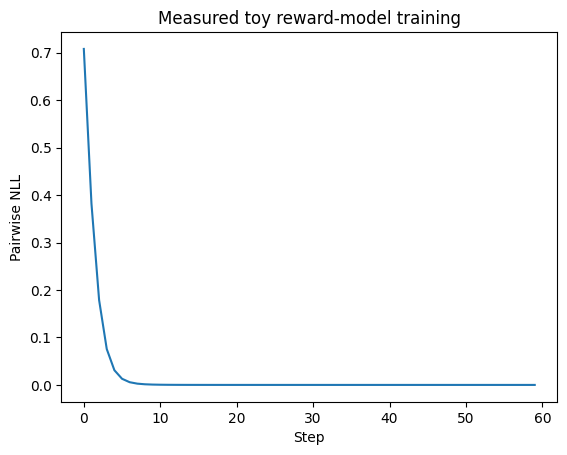

Training: {'pair_accuracy': 1.0, 'pair_nll': 2.25437884182611e-06} Validation: {'pair_accuracy': 1.0, 'pair_nll': 0.071455217897892}


In [3]:
print(rows[0])
longer=sum(len(r['chosen'])>len(r['rejected']) for r in rows)
print('Chosen longer in characters:',longer,'/',len(rows))
# Train-only bag-of-word vocabulary; no large models or tokenizers.
terms=sorted(set(re.findall(r'\w+', ' '.join(r[k].lower() for r in train_rows for k in r))))
lookup={w:i for i,w in enumerate(terms)}
def features(examples,side):
    result=torch.zeros(len(examples),len(lookup)+1)
    for i,r in enumerate(examples):
        for word in re.findall(r'\w+', (r['prompt']+' '+r[side]).lower()):
            if word in lookup:result[i,lookup[word]]+=1
        result[i,-1]=len(r[side])/100. # explicit length feature exposes confound
    return result
reward_model=nn.Sequential(nn.Linear(len(lookup)+1,24),nn.Tanh(),nn.Linear(24,1))
opt=torch.optim.Adam(reward_model.parameters(),lr=.02);history=[]
xw=features(train_rows,'chosen');xl=features(train_rows,'rejected')
for step in range(60):
    rw=reward_model(xw).squeeze(-1);rl=reward_model(xl).squeeze(-1)
    loss=F.softplus(-(rw-rl)).mean();opt.zero_grad();loss.backward()
    assert torch.isfinite(loss) and all(torch.isfinite(p.grad).all() for p in reward_model.parameters())
    opt.step();history.append(loss.item())
plt.plot(history);plt.xlabel('Step');plt.ylabel('Pairwise NLL');plt.title('Measured toy reward-model training');plt.show()
@torch.no_grad()
def rm_metrics(examples):
    d=(reward_model(features(examples,'chosen'))-reward_model(features(examples,'rejected'))).squeeze(-1)
    return {'pair_accuracy':d.gt(0).float().mean().item(),'pair_nll':F.softplus(-d).mean().item()}
print('Training:',rm_metrics(train_rows),'Validation:',rm_metrics(valid_rows))
reward_model.eval().requires_grad_(False)
assert all(not p.requires_grad for p in reward_model.parameters())

## Bias and validation

All20 chosen answers are longer in characters. A reward model can exploit length; add balanced counterexamples, prompt diversity and independent tests. The bag-of-words scorer cannot model nuanced semantics, contradictions or prompt-dependent reasoning. Evaluate a separate task suite and scorer calibration before using rewards for RL. The local file has no numeric reward scores, reference answers, annotation confidence or splits; this notebook creates a split and does not invent those fields.

## Exercises

1. Remove length feature and compare validation rankings.
2. Test rewards on repeated words or verbose wrong answers.
3. Fit logistic calibration on a separate, larger comparison set.

## Key takeaways

Recompute the worked examples, inspect masks and gradients, and evaluate independently of the training objective. A small training-loss decrease does not establish generalization or alignment. Record the model, data split, seeds and dependency versions before interpreting results.